In [5]:

import os

print(os.listdir('/content'))


['.config', 'sample_data']


In [6]:

import pandas as pd
import glob

# Find uploaded cleaned CSV file
files = glob.glob('/content/Cleaned_StudentsPerformance*.csv')

print("Files found:", files)

if files:
    df = pd.read_csv(files[0])
    print("Dataset loaded successfully!")
    print(df.head())
else:
    print("Cleaned CSV file not found!")


Files found: []
Cleaned CSV file not found!


In [7]:

import os

for file in os.listdir('/content'):
    print(repr(file))


'.config'
'sample_data'


In [8]:

import pandas as pd
import os

print(os.listdir('/content'))

df = pd.read_csv('/content/Cleaned_StudentsPerformance.csv')

print("Dataset Loaded Successfully!")
print(df.head())


['.config', 'sample_data']


FileNotFoundError: [Errno 2] No such file or directory: '/content/Cleaned_StudentsPerformance.csv'

In [9]:

from google.colab import files

uploaded = files.upload()


Saving Cleaned_StudentsPerformance.csv to Cleaned_StudentsPerformance.csv


In [10]:

import pandas as pd

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset Loaded Successfully!")
print(df.head())


Dataset Loaded Successfully!
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [11]:

# Check dataset information
print("Dataset Shape:")
print(df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Summary Statistics
print("\nSummary Statistics:")
print(df.describe())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())


Dataset Shape:
(1000, 8)

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Summary Statistics:
       math score  reading score  writing score
count  1000.00000    1000.000000    1000.000000
mean     66.08900      69.169000      68.054000
std      15.16308      14.600192      15.195657
min       0.00000      17.000000      10.000000
25%      57.00000      59.000000      57.750000
50%      66.00000      70.000000      69.000000
75%      77.00000      79.000000      79.000000
max     100.00000     100.000000     100.000000

Duplicate Records:
0


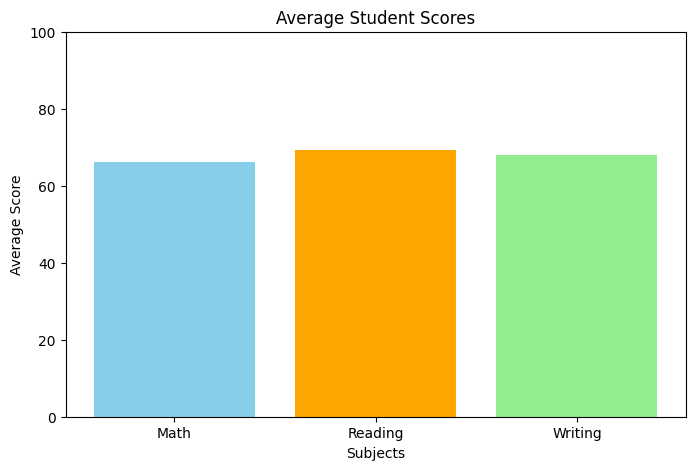

In [12]:

import matplotlib.pyplot as plt

# Calculate average scores
subjects = ['Math', 'Reading', 'Writing']

average_scores = [
    df['math score'].mean(),
    df['reading score'].mean(),
    df['writing score'].mean()
]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(subjects, average_scores,
        color=['skyblue', 'orange', 'lightgreen'])

plt.title('Average Student Scores')
plt.xlabel('Subjects')
plt.ylabel('Average Score')
plt.ylim(0, 100)

plt.show()


Gender-wise Average Scores:
        math score  reading score  writing score
gender                                          
female       63.63          72.61          72.47
male         68.73          65.47          63.31


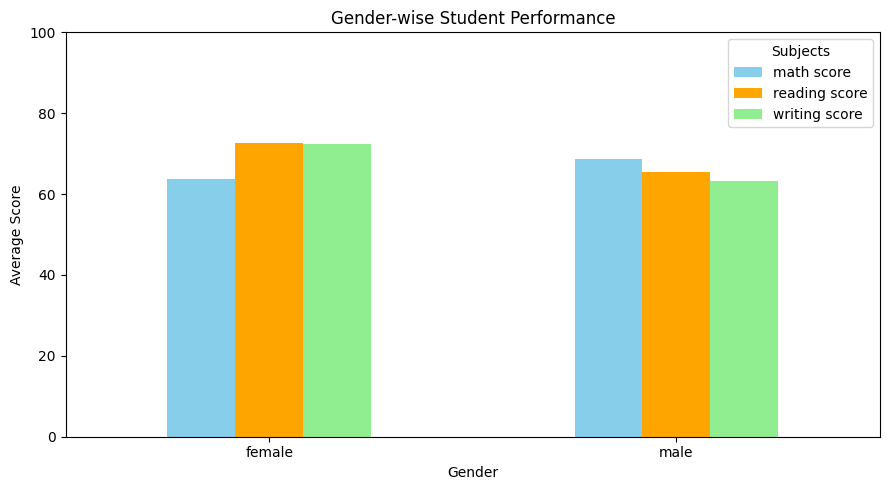

In [13]:

import pandas as pd
import matplotlib.pyplot as plt

# Calculate average scores by gender
gender_scores = df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].mean()

# Display results
print("Gender-wise Average Scores:")
print(gender_scores.round(2))

# Create chart
gender_scores.plot(
    kind='bar',
    figsize=(9, 5),
    color=['skyblue', 'orange', 'lightgreen']
)

plt.title('Gender-wise Student Performance')
plt.xlabel('Gender')
plt.ylabel('Average Score')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()


Test Preparation Course Analysis:
                         math score  reading score  writing score
test preparation course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50


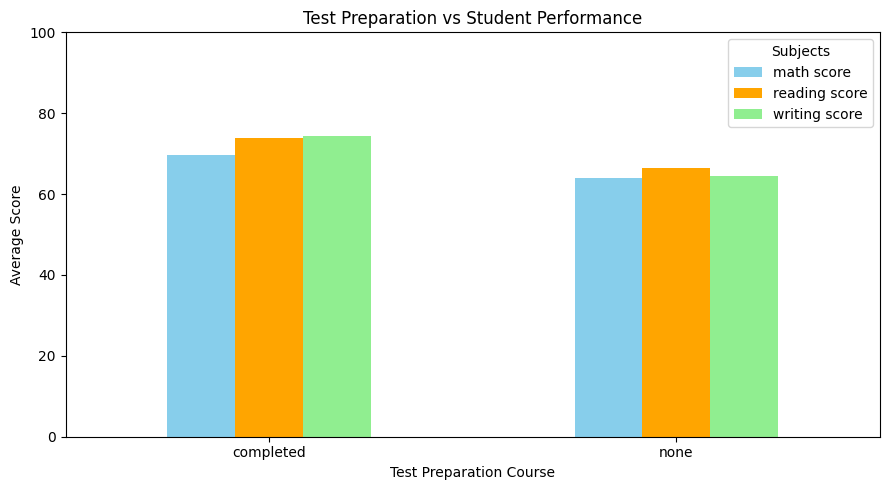

In [14]:

import matplotlib.pyplot as plt

# Calculate average scores by test preparation
prep_scores = df.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].mean()

# Display results
print("Test Preparation Course Analysis:")
print(prep_scores.round(2))

# Create bar chart
prep_scores.plot(
    kind='bar',
    figsize=(9, 5),
    color=['skyblue', 'orange', 'lightgreen']
)

plt.title('Test Preparation vs Student Performance')
plt.xlabel('Test Preparation Course')
plt.ylabel('Average Score')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()


Lunch-wise Average Scores:
              math score  reading score  writing score
lunch                                                 
free/reduced       58.92          64.65          63.02
standard           70.03          71.65          70.82


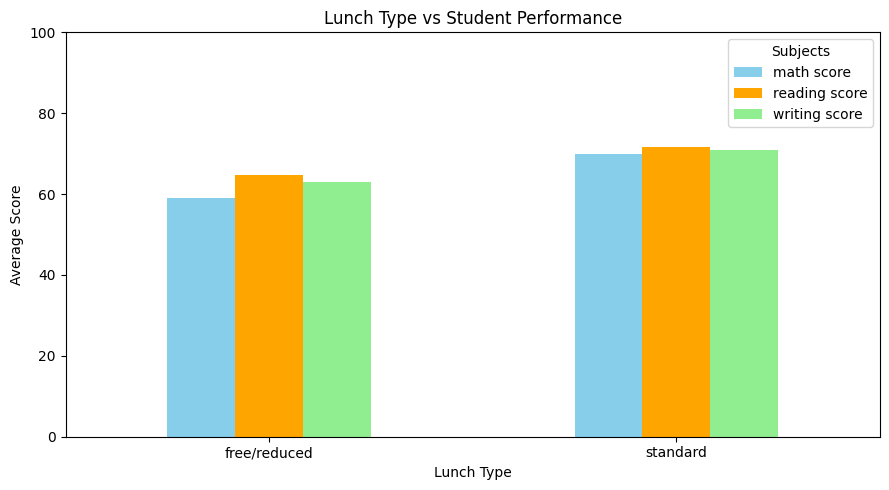

In [15]:

import matplotlib.pyplot as plt

# Calculate average scores by lunch type
lunch_scores = df.groupby('lunch')[
    ['math score', 'reading score', 'writing score']
].mean()

print("Lunch-wise Average Scores:")
print(lunch_scores.round(2))

# Create bar chart
lunch_scores.plot(
    kind='bar',
    figsize=(9, 5),
    color=['skyblue', 'orange', 'lightgreen']
)

plt.title('Lunch Type vs Student Performance')
plt.xlabel('Lunch Type')
plt.ylabel('Average Score')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()


Parental Education-wise Average Scores:
                             math score  reading score  writing score
parental level of education                                          
associate's degree                67.88          70.93          69.90
bachelor's degree                 69.39          73.00          73.38
high school                       62.14          64.70          62.45
master's degree                   69.75          75.37          75.68
some college                      67.13          69.46          68.84
some high school                  63.50          66.94          64.89


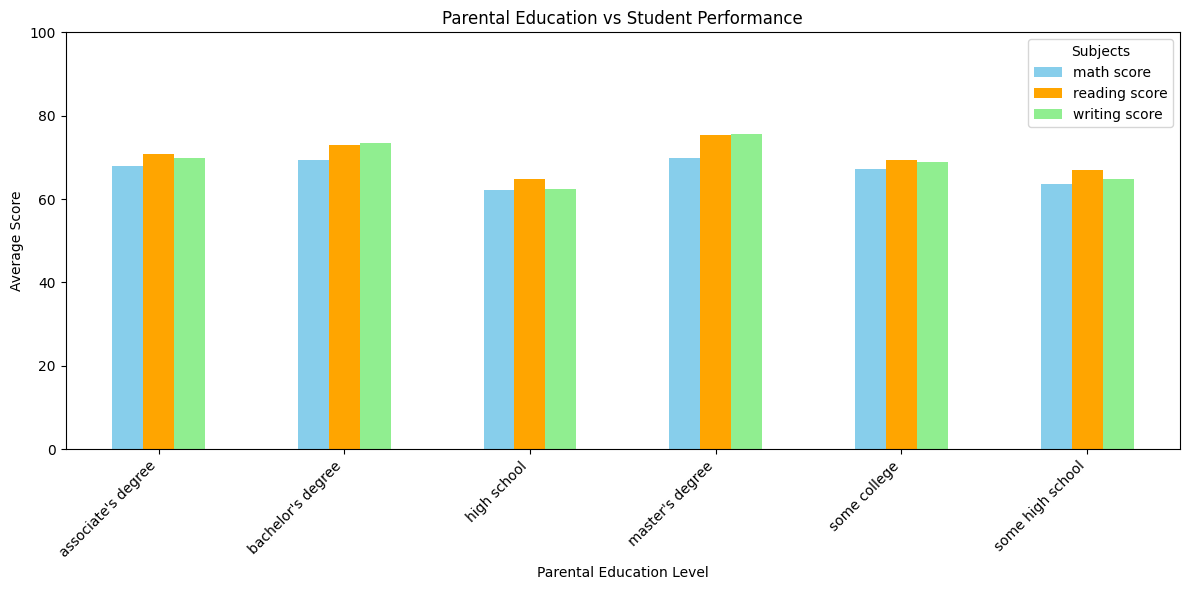

In [16]:

import matplotlib.pyplot as plt

# Calculate average scores by parental education
education_scores = df.groupby(
    'parental level of education'
)[['math score', 'reading score', 'writing score']].mean()

# Display average scores
print("Parental Education-wise Average Scores:")
print(education_scores.round(2))

# Create chart
education_scores.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'orange', 'lightgreen']
)

plt.title('Parental Education vs Student Performance')
plt.xlabel('Parental Education Level')
plt.ylabel('Average Score')
plt.ylim(0, 100)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()


In [17]:

score_cols = ['math score', 'reading score', 'writing score']

print("1. Overall Average Scores:")
print(df[score_cols].mean().round(2))

print("\n2. Gender-wise Average Scores:")
print(df.groupby('gender')[score_cols].mean().round(2))

print("\n3. Test Preparation Analysis:")
print(df.groupby('test preparation course')[score_cols].mean().round(2))

print("\n4. Lunch Type Analysis:")
print(df.groupby('lunch')[score_cols].mean().round(2))

print("\n5. Parental Education Analysis:")
print(df.groupby('parental level of education')[score_cols].mean().round(2))


1. Overall Average Scores:
math score       66.09
reading score    69.17
writing score    68.05
dtype: float64

2. Gender-wise Average Scores:
        math score  reading score  writing score
gender                                          
female       63.63          72.61          72.47
male         68.73          65.47          63.31

3. Test Preparation Analysis:
                         math score  reading score  writing score
test preparation course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50

4. Lunch Type Analysis:
              math score  reading score  writing score
lunch                                                 
free/reduced       58.92          64.65          63.02
standard           70.03          71.65          70.82

5. Parental Education Analysis:
                             math score  reading score  writing score
parental level of 

## Key Insights from Exploratory Data Analysis

**Insight 1: Overall Student Performance**

The average Reading score (69.17) is the highest among the three subjects, followed by Writing (68.05) and Mathematics (66.09). This indicates that students performed relatively better in Reading than in Mathematics.

**Insight 2: Gender-wise Performance**

Female students achieved higher average scores in Reading (72.61) and Writing (72.47), while male students performed better in Mathematics (68.73 compared to 63.63 for female students).

**Insight 3: Test Preparation Course**

Students who completed the test preparation course achieved higher average scores in all three subjects. Their average Writing score was 74.42, compared to 64.50 for students who did not complete the course.

**Insight 4: Lunch Type and Academic Performance**

Students receiving standard lunch had higher average scores in Mathematics (70.03), Reading (71.65), and Writing (70.82) compared to students receiving free/reduced lunch.

**Insight 5: Mathematics Performance Gap**

Mathematics had the lowest overall average score (66.09). The average Mathematics score for students receiving free/reduced lunch was 58.92, compared to 70.03 for students receiving standard lunch, a difference of 11.11 points.